# Forecast Evaluation and Backtesting

Companion to [the forecast-evaluation note](../../notes/time_series/forecast_evaluation.md). We reproduce the by-hand metric calculations, run a rolling-origin experiment, scale errors with MASE, check interval coverage, demonstrate leakage, and look at error by horizon. See also the existing [forecast_backtesting notebook](forecast_backtesting.ipynb).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
def metrics(actual, fc, scale=None):
    e = np.asarray(actual) - np.asarray(fc)
    out = {"ME": e.mean(), "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e**2).mean())}
    if scale: out["MASE"] = out["MAE"]/scale
    return out

# note: actual (10,12,9), forecasts (9,11,10), in-sample naive scale 2
print(metrics([10,12,9],[9,11,10],scale=2))
# expanding window example: naive one-step forecasts at origins 3..6
y = np.array([10,12,11,14,13,16,15])
act = y[3:]; fc = y[2:-1]
print("errors:", act-fc)
print(metrics(act, fc))

{'ME': np.float64(0.3333333333333333), 'MAE': np.float64(1.0), 'RMSE': np.float64(1.0), 'MASE': np.float64(0.5)}
errors: [ 3 -1  3 -1]
{'ME': np.float64(1.0), 'MAE': np.float64(2.0), 'RMSE': np.float64(2.23606797749979)}


The hand results are MAE $=1$, RMSE $=1$, MASE $=0.5$ for the first example and errors $(3,-1,3,-1)$, MAE $=2$, RMSE $=\sqrt5\approx2.236$, ME $=1$ for the second. A positive mean error under $e=y-\hat y$ means underforecasting on average.

In [2]:
from statsmodels.tsa.ar_model import AutoReg
rng = np.random.default_rng(7)
n = 200
x = np.zeros(n)
for i in range(1, n):
    x[i] = 0.7*x[i-1] + rng.normal()
start = 100
rows = {"naive": [], "AR(1)": [], "mean": []}
acts, scales = [], []
for o in range(start, n-1):
    tr = x[:o+1]
    acts.append(x[o+1])
    rows["naive"].append(tr[-1])
    rows["mean"].append(tr.mean())
    rows["AR(1)"].append(AutoReg(tr, lags=1).fit().predict(start=len(tr), end=len(tr))[0])
    scales.append(np.mean(np.abs(np.diff(tr))))      # scale recomputed on training window only
acts = np.array(acts)
for k,v in rows.items():
    e = acts-np.array(v)
    mase = np.mean(np.abs(e))/np.mean(scales)
    print(f"{k:6s} MAE={np.mean(np.abs(e)):.3f} RMSE={np.sqrt(np.mean(e**2)):.3f} ME={e.mean():+.3f} MASE={mase:.3f}")

naive  MAE=0.753 RMSE=0.955 ME=+0.043 MASE=0.996
AR(1)  MAE=0.687 RMSE=0.866 ME=+0.068 MASE=0.909
mean   MAE=0.842 RMSE=1.092 ME=+0.083 MASE=1.114


At each origin the model is refit on past data only (expanding window) and the MASE scale is computed on the same training window, so nothing from the future enters. For this AR(1) data the fitted AR(1) should beat both the naive and the historical-mean baseline.

In [3]:
# Interval coverage and sharpness: Gaussian 80% and 95% intervals from AR(1) one-step errors
errs = acts - np.array(rows["AR(1)"])
sd = errs.std(ddof=1)
for level, z in [(0.80,1.2816),(0.95,1.96)]:
    cover = np.mean(np.abs(errs) <= z*sd)
    print(f"nominal {level:.2f}: empirical coverage {cover:.3f}, width {2*z*sd:.2f}")
def interval_score(y, L, U, a):
    return (U-L) + 2/a*(L-y)*(y<L) + 2/a*(y-U)*(y>U)
a=0.05
print("mean interval score (95%):", np.mean(interval_score(acts, np.array(rows["AR(1)"])-1.96*sd, np.array(rows["AR(1)"])+1.96*sd, a)).round(3))

nominal 0.80: empirical coverage 0.788, width 2.22
nominal 0.95: empirical coverage 0.960, width 3.40
mean interval score (95%): 3.927


Coverage alone is not sufficient (infinite intervals cover everything): report width and the interval score, which penalises both width and misses. Here the in-sample $\hat\sigma$ is used, which is slightly optimistic; a strict backtest would estimate $\sigma$ from past errors at each origin.

In [4]:
# Leakage: standardising with full-sample mean/sd vs training-only statistics
rng = np.random.default_rng(11)
trend = 0.1*np.arange(120) + rng.normal(size=120)
split = 80
safe = (trend[split:] - trend[:split].mean())/trend[:split].std()
leaky = (trend[split:] - trend.mean())/trend.std()
print("test-period mean after safe scaling :", safe.mean().round(2))
print("test-period mean after leaky scaling:", leaky.mean().round(2))

test-period mean after safe scaling : 2.38
test-period mean after leaky scaling: 1.1


With a trending series the training-only statistics reveal that the test period is far above the training range, while full-sample scaling hides much of this shift: the preprocessing has used information from after the forecast origin. Every transformation must be fit inside each training window.

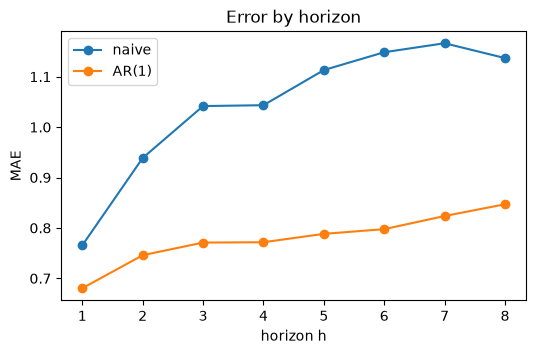

In [5]:
# Error by horizon: naive vs AR(1) for h = 1..8 using direct multi-step forecasts
H = 8
res = {"naive": np.zeros(H), "AR(1)": np.zeros(H)}
cnt = 0
phi_hat = None
for o in range(100, n-H):
    tr = x[:o+1]
    m = AutoReg(tr, lags=1).fit()
    c, p = m.params
    f = tr[-1]; g = tr[-1]
    for j in range(H):
        f = c + p*f
        res["AR(1)"][j] += abs(x[o+1+j]-f)
        res["naive"][j] += abs(x[o+1+j]-tr[-1])
    cnt += 1
plt.figure(figsize=(6,3.5))
for k,v in res.items(): plt.plot(range(1,H+1), v/cnt, "o-", label=k)
plt.xlabel("horizon h"); plt.ylabel("MAE"); plt.legend(); plt.title("Error by horizon"); plt.show()

Naive error grows with the horizon until it plateaus near the series' own spread, whereas AR(1) forecasts revert to the mean and keep a lower error. A single averaged score would hide this horizon-dependence, so report accuracy at the horizons used in decisions.